In [1]:
import pandas as pd
import numpy as np
import random

import torch
from torch.utils.data import TensorDataset, DataLoader, Dataset
import torch.nn as nn
from torch import optim

from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

In [2]:
train_data = pd.read_csv("../data/rck_growth_train.csv")
test_data = pd.read_csv("../data/rck_growth_test.csv")

In [3]:
train_data.head()

,alpha,delta,rho,theta,n,g,k0_initial,c0_initial,t_grid_0,t_grid_1,...,c_t90,c_t91,c_t92,c_t93,c_t94,c_t95,c_t96,c_t97,c_t98,c_t99
0,0.320942,0.078504,0.036714,2.667830,0.025523,0.020701,2.841608,1.071450,0.0,0.20202,...,0.998946,0.997710,0.996449,0.995163,0.993850,0.992511,0.991143,0.989748,0.988324,0.986871
1,0.370546,0.051380,0.027702,2.473983,0.028726,0.011280,8.130883,1.302195,0.0,0.20202,...,1.143203,1.140566,1.137913,1.135245,1.132561,1.129863,1.127150,1.124423,1.121682,1.118926
2,0.398416,0.030995,0.037961,1.879368,0.010810,0.018058,11.143902,1.515309,0.0,0.20202,...,1.160572,1.155156,1.149729,1.144292,1.138846,1.133392,1.127930,1.122460,1.116984,1.111502
3,0.326263,0.055221,0.039762,2.254829,0.011356,0.024472,3.550989,1.069716,0.0,0.20202,...,0.752742,0.747704,0.742662,0.737619,0.732573,0.727528,0.722482,0.717439,0.712397,0.707359
4,0.345689,0.053755,0.025442,2.950059,0.023943,0.011664,6.273021,1.300522,0.0,0.20202,...,1.186080,1.184205,1.182313,1.180406,1.178482,1.176543,1.174587,1.172615,1.170627,1.168623


In [4]:
# Parameters
print(*train_data.iloc[:, :8].columns, sep='\n')

alpha
delta
rho
theta
n
g
k0_initial
c0_initial


In [5]:
# Grid
print(len(train_data.filter(like='t_grid').columns))
train_data.filter(like='t_grid')

100


,t_grid_0,t_grid_1,t_grid_2,t_grid_3,t_grid_4,t_grid_5,t_grid_6,t_grid_7,t_grid_8,t_grid_9,...,t_grid_90,t_grid_91,t_grid_92,t_grid_93,t_grid_94,t_grid_95,t_grid_96,t_grid_97,t_grid_98,t_grid_99
0,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
1,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
2,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
3,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
4,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1595,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
1596,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
1597,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0
1598,0.0,0.20202,0.40404,0.606061,0.808081,1.010101,1.212121,1.414141,1.616162,1.818182,...,18.181818,18.383838,18.585859,18.787879,18.989899,19.191919,19.393939,19.59596,19.79798,20.0


In [6]:
# k values (grid as arg)
print(len(train_data.filter(like='k_t').columns))
train_data.filter(like='k_t')

100


,k_t0,k_t1,k_t2,k_t3,k_t4,k_t5,k_t6,k_t7,k_t8,k_t9,...,k_t90,k_t91,k_t92,k_t93,k_t94,k_t95,k_t96,k_t97,k_t98,k_t99
0,2.841608,2.836099,2.830755,2.825574,2.820552,2.815688,2.810980,2.806425,2.802020,2.797765,...,2.940884,2.950721,2.960869,2.971335,2.982124,2.993243,3.004699,3.016497,3.028646,3.041151
1,8.130883,8.156989,8.183309,8.209846,8.236603,8.263585,8.290795,8.318235,8.345909,8.373822,...,11.680055,11.735959,11.792249,11.848925,11.905986,11.963432,12.021261,12.079474,12.138068,12.197043
2,11.143902,11.231363,11.319739,11.409041,11.499281,11.590472,11.682625,11.775753,11.869866,11.964975,...,23.576737,23.769258,23.962849,24.157502,24.353206,24.549952,24.747731,24.946531,25.146343,25.347157
3,3.550989,3.575256,3.599986,3.625193,3.650891,3.677092,3.703810,3.731059,3.758852,3.787202,...,8.780686,8.877892,8.975799,9.074396,9.173668,9.273603,9.374186,9.475404,9.577242,9.679686
4,6.273021,6.278266,6.283701,6.289328,6.295148,6.301163,6.307373,6.313781,6.320388,6.327196,...,7.738519,7.769226,7.800318,7.831797,7.863664,7.895922,7.928573,7.961619,7.995061,8.028901
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1595,7.022164,6.987785,6.953668,6.919804,6.886182,6.852792,6.819625,6.786669,6.753915,6.721353,...,3.602752,3.535412,3.466164,3.394898,3.321500,3.245849,3.167818,3.087275,3.004082,2.918096
1596,3.720665,3.762529,3.805020,3.848157,3.891956,3.936434,3.981607,4.027491,4.074102,4.121456,...,10.974716,11.091809,11.209359,11.327350,11.445765,11.564586,11.683796,11.803377,11.923313,12.043584
1597,4.358816,4.369889,4.380885,4.391806,4.402655,4.413434,4.424145,4.434791,4.445374,4.455898,...,5.318215,5.331471,5.344852,5.358361,5.372000,5.385771,5.399677,5.413720,5.427902,5.442226
1598,3.505986,3.503145,3.500392,3.497727,3.495150,3.492659,3.490256,3.487938,3.485708,3.483563,...,3.680269,3.690055,3.700130,3.710499,3.721167,3.732140,3.743424,3.755025,3.766947,3.779198


In [7]:
# c values (grid as arg)
print(len(train_data.filter(like='c_t').columns))
train_data.filter(like='c_t')

100


,c_t0,c_t1,c_t2,c_t3,c_t4,c_t5,c_t6,c_t7,c_t8,c_t9,...,c_t90,c_t91,c_t92,c_t93,c_t94,c_t95,c_t96,c_t97,c_t98,c_t99
0,1.071450,1.070442,1.069452,1.068479,1.067523,1.066583,1.065658,1.064749,1.063854,1.062974,...,0.998946,0.997710,0.996449,0.995163,0.993850,0.992511,0.991143,0.989748,0.988324,0.986871
1,1.302195,1.301343,1.300470,1.299577,1.298662,1.297727,1.296772,1.295795,1.294798,1.293780,...,1.143203,1.140566,1.137913,1.135245,1.132561,1.129863,1.127150,1.124423,1.121682,1.118926
2,1.515309,1.513731,1.512084,1.510368,1.508584,1.506730,1.504809,1.502821,1.500765,1.498642,...,1.160572,1.155156,1.149729,1.144292,1.138846,1.133392,1.127930,1.122460,1.116984,1.111502
3,1.069716,1.068609,1.067442,1.066215,1.064928,1.063580,1.062171,1.060701,1.059169,1.057576,...,0.752742,0.747704,0.742662,0.737619,0.732573,0.727528,0.722482,0.717439,0.712397,0.707359
4,1.300522,1.299661,1.298796,1.297925,1.297050,1.296170,1.295284,1.294393,1.293496,1.292594,...,1.186080,1.184205,1.182313,1.180406,1.178482,1.176543,1.174587,1.172615,1.170627,1.168623
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1595,1.403985,1.402849,1.401753,1.400697,1.399680,1.398702,1.397763,1.396864,1.396004,1.395183,...,1.512011,1.518010,1.524304,1.530913,1.537862,1.545172,1.552870,1.560983,1.569538,1.578564
1596,1.022591,1.021772,1.020854,1.019838,1.018725,1.017516,1.016211,1.014811,1.013316,1.011728,...,0.678496,0.673371,0.668255,0.663147,0.658049,0.652961,0.647885,0.642820,0.637768,0.632730
1597,1.088697,1.089224,1.089736,1.090232,1.090713,1.091179,1.091629,1.092065,1.092485,1.092891,...,1.082460,1.081806,1.081140,1.080461,1.079769,1.079065,1.078349,1.077620,1.076878,1.076124
1598,1.219959,1.219365,1.218778,1.218198,1.217625,1.217057,1.216496,1.215940,1.215390,1.214846,...,1.167541,1.166584,1.165606,1.164609,1.163590,1.162551,1.161489,1.160406,1.159299,1.158170


# Classic DeepONet architecture

In [8]:
grid_size = 100

params_cols = ['alpha', 'delta', 'rho', 'theta', 'n', 'g', 'k0_initial', 'c0_initial']
t_grid_cols = [f't_grid_{i}' for i in range(grid_size)]
k_cols = [f'k_t{i}' for i in range(grid_size)]
c_cols = [f'c_t{i}' for i in range(grid_size)]

scaler_params = StandardScaler().fit(train_data[params_cols].values)
scaler_k = StandardScaler().fit(train_data[k_cols].values)
scaler_c = StandardScaler().fit(train_data[c_cols].values)

def prepare_deeponet_tensors(df, scaler_p, scaler_k_obj, scaler_c_obj):
    num_samples = len(df)
    
    # Extract and scale
    params_scaled = scaler_p.transform(df[params_cols].values)
    t_grid = df[t_grid_cols].values
    k_traj_scaled = scaler_k_obj.transform(df[k_cols].values)
    c_traj_scaled = scaler_c_obj.transform(df[c_cols].values)
    
    # BRANCH INPUT
    # (N, 8)
    X_branch = torch.tensor(params_scaled, dtype=torch.float32)
    
    # TRUNK INPUT
    # (N, 100) -> (N * 100, 1)
    X_trunk = torch.tensor(t_grid, dtype=torch.float32).reshape(-1, 1)
    
    # Y
    k_flat = k_traj_scaled.reshape(-1, 1)
    c_flat = c_traj_scaled.reshape(-1, 1)
    Y = torch.tensor(np.hstack([k_flat, c_flat]), dtype=torch.float32)
    
    # (N*100, 8)
    X_branch_expanded = X_branch.repeat_interleave(grid_size, dim=0)

    return X_branch_expanded, X_trunk, Y

X_branch_train, X_trunk_train, Y_train = prepare_deeponet_tensors(train_data, scaler_params, scaler_k, scaler_c)
X_branch_test, X_trunk_test, Y_test = prepare_deeponet_tensors(test_data, scaler_params, scaler_k, scaler_c)

print(f"X_branch: {X_branch_train.shape}")  # Expected: [N_train * 100, 1, 8]
print(f"X_trunk:  {X_trunk_train.shape}")   # Expected: [N_train * 100, 1]
print(f"Y (Target):{Y_train.shape}")         # Expected: [N_train * 100, 2]

# 4. Create DeepONet DataLoaders
train_dataset = TensorDataset(X_branch_train, X_trunk_train, Y_train)
test_dataset = TensorDataset(X_branch_test, X_trunk_test, Y_test)

# Using a larger batch size because the dataset size multiplied by 100
train_loader = DataLoader(train_dataset, batch_size=2048, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=2048, shuffle=False)

X_branch: torch.Size([160000, 8])
X_trunk:  torch.Size([160000, 1])
Y (Target):torch.Size([160000, 2])


In [ ]:
class DeepONet(nn.Module):
    def __init__(self, branch_input_dim=8, num_modes=64, branch_hidden=128, trunk_hidden=128):
        super().__init__()
        self.num_modes = num_modes

        # BRANCH
        self.branch = nn.Sequential(
            nn.Linear(branch_input_dim, branch_hidden),
            nn.ReLU(),
            nn.Linear(branch_hidden, branch_hidden),
            nn.ReLU(),
            nn.Linear(branch_hidden, num_modes * 2)
        )

        # TRUNK
        self.trunk = nn.Sequential(
            nn.Linear(1, trunk_hidden),
            nn.ReLU(),
            nn.Linear(trunk_hidden, trunk_hidden),
            nn.ReLU(),
            nn.Linear(trunk_hidden, num_modes * 2)
        )

    def forward(self, x_branch, x_trunk):
        # Branch output
        b_out = self.branch(x_branch)

        # Trunk output
        t_out = self.trunk(x_trunk)

        # Split latent spaces
        b_k, b_c = torch.split(b_out, self.num_modes, dim=-1)
        t_k, t_c = torch.split(t_out, self.num_modes, dim=-1)

        # Dot products
        out_k = torch.sum(b_k * t_k, dim=-1, keepdim=True)
        out_c = torch.sum(b_c * t_c, dim=-1, keepdim=True)

        return torch.cat([out_k, out_c], dim=-1)

In [10]:
NUM_TRIALS = 10
TRIAL_EPOCHS = 5
FINAL_EPOCHS = 100

hyperparameter_space = {
    'num_modes': [32, 64, 128],
    'branch_hidden': [64, 128, 256],
    'trunk_hidden': [64, 128, 256],
    'lr': [1e-3, 3e-4, 1e-4],
    'weight_decay': [1e-5, 1e-4]
}

best_val_loss = float('inf')
best_hparams = None

print(f"---  DeepONet Random Search ({NUM_TRIALS} Trials) ---")

for trial in range(NUM_TRIALS):
    hparams = {key: random.choice(values) for key, values in hyperparameter_space.items()}
    print(f"\n[Trial {trial+1}/{NUM_TRIALS}] Evaluation Stack: {hparams}")
    
    #  current trial candidate
    model = DeepONet(
        branch_input_dim=8,
        num_modes=hparams['num_modes'],
        branch_hidden=hparams['branch_hidden'],
        trunk_hidden=hparams['trunk_hidden']
    )
    
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=hparams['lr'], weight_decay=hparams['weight_decay'])
    
    model.train()
    for epoch in range(TRIAL_EPOCHS):
        for x_b, x_t, y in train_loader:
            optimizer.zero_grad()
            pred = model(x_b, x_t)
            loss = criterion(pred, y)
            loss.backward()
            optimizer.step()
            
    # Evaluation Pass
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_b, x_t, y in test_loader:
            pred = model(x_b, x_t)
            loss = criterion(pred, y)
            val_loss += loss.item() * x_b.size(0)
    val_loss /= len(test_loader.dataset)
    
    print(f"Trial {trial+1}  Val Loss (MSE): {val_loss:.6f}")
    
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_hparams = hparams

print(f"Best Configuration: {best_hparams}")

---  DeepONet Random Search (10 Trials) ---

[Trial 1/10] Evaluation Stack: {'num_modes': 64, 'branch_hidden': 64, 'trunk_hidden': 256, 'lr': 0.0003, 'weight_decay': 0.0001}
Trial 1  Val Loss (MSE): 0.025254

[Trial 2/10] Evaluation Stack: {'num_modes': 32, 'branch_hidden': 256, 'trunk_hidden': 256, 'lr': 0.0003, 'weight_decay': 0.0001}
Trial 2  Val Loss (MSE): 0.010062

[Trial 3/10] Evaluation Stack: {'num_modes': 64, 'branch_hidden': 256, 'trunk_hidden': 128, 'lr': 0.001, 'weight_decay': 0.0001}
Trial 3  Val Loss (MSE): 0.006612

[Trial 4/10] Evaluation Stack: {'num_modes': 128, 'branch_hidden': 256, 'trunk_hidden': 128, 'lr': 0.001, 'weight_decay': 1e-05}
Trial 4  Val Loss (MSE): 0.014493

[Trial 5/10] Evaluation Stack: {'num_modes': 32, 'branch_hidden': 64, 'trunk_hidden': 256, 'lr': 0.001, 'weight_decay': 1e-05}
Trial 5  Val Loss (MSE): 0.014044

[Trial 6/10] Evaluation Stack: {'num_modes': 128, 'branch_hidden': 256, 'trunk_hidden': 256, 'lr': 0.0003, 'weight_decay': 1e-05}
Trial 

In [11]:
print(f"\n---  Final Model for {FINAL_EPOCHS} Epochs ---")

final_deeponet = DeepONet(
    branch_input_dim=8,
    num_modes=best_hparams['num_modes'],
    branch_hidden=best_hparams['branch_hidden'],
    trunk_hidden=best_hparams['trunk_hidden']
)

criterion = nn.MSELoss()
optimizer = optim.Adam(final_deeponet.parameters(), lr=best_hparams['lr'], weight_decay=best_hparams['weight_decay'])
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=6, factor=0.5)

train_losses = []
val_losses = []

for epoch in range(FINAL_EPOCHS):
    final_deeponet.train()
    train_loss = 0.0
    for x_b, x_t, y in train_loader:
        optimizer.zero_grad()
        pred = final_deeponet(x_b, x_t)
        loss = criterion(pred, y)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * x_b.size(0)
    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)
    
    final_deeponet.eval()
    val_loss = 0.0
    with torch.no_grad():
        for x_b, x_t, y in test_loader:
            pred = final_deeponet(x_b, x_t)
            loss = criterion(pred, y)
            val_loss += loss.item() * x_b.size(0)
    val_loss /= len(test_loader.dataset)
    val_losses.append(val_loss)
    
    scheduler.step(val_loss)
    
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{FINAL_EPOCHS}] -> Running Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")


---  Final Model for 100 Epochs ---
Epoch [1/100] -> Running Train Loss: 0.491486 | Val Loss: 0.031860
Epoch [10/100] -> Running Train Loss: 0.002834 | Val Loss: 0.006515
Epoch [20/100] -> Running Train Loss: 0.001611 | Val Loss: 0.005787
Epoch [30/100] -> Running Train Loss: 0.000907 | Val Loss: 0.004985
Epoch [40/100] -> Running Train Loss: 0.005567 | Val Loss: 0.003996
Epoch [50/100] -> Running Train Loss: 0.000922 | Val Loss: 0.004983
Epoch [60/100] -> Running Train Loss: 0.000429 | Val Loss: 0.003385
Epoch [70/100] -> Running Train Loss: 0.000571 | Val Loss: 0.003264
Epoch [80/100] -> Running Train Loss: 0.000485 | Val Loss: 0.003360
Epoch [90/100] -> Running Train Loss: 0.000411 | Val Loss: 0.002933
Epoch [100/100] -> Running Train Loss: 0.000335 | Val Loss: 0.002686


In [12]:
final_deeponet.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for x_b, x_t, y in test_loader:
        pred = final_deeponet(x_b, x_t) # Shape: [Batch, 2]
        all_preds.append(pred.numpy())
        all_targets.append(y.numpy())

all_preds = np.concatenate(all_preds, axis=0)     # Shape: (N_test * 100, 2)
all_targets = np.concatenate(all_targets, axis=0) # Shape: (N_test * 100, 2)

# Reshape back from single data streams to original grid sequences: (N_test, 100, 2)
num_test_simulations = len(test_data)
all_preds = all_preds.reshape(num_test_simulations, grid_size, 2)
all_targets = all_targets.reshape(num_test_simulations, grid_size, 2)

# Unscale channels
preds_k = scaler_k.inverse_transform(all_preds[:, :, 0])
preds_c = scaler_c.inverse_transform(all_preds[:, :, 1])
targets_k = scaler_k.inverse_transform(all_targets[:, :, 0])
targets_c = scaler_c.inverse_transform(all_targets[:, :, 1])

# Extract time coordinates
time_axis = test_data[[f't_grid_{i}' for i in range(grid_size)]].iloc[0].values

# Compute Absolute Errors
abs_error_k = np.abs(targets_k - preds_k)
abs_error_c = np.abs(targets_c - preds_c)

## Results

In [13]:
import os
import matplotlib.pyplot as plt

output_dir = "../Plots/Deep_onet_rck_plots"
os.makedirs(output_dir, exist_ok=True)

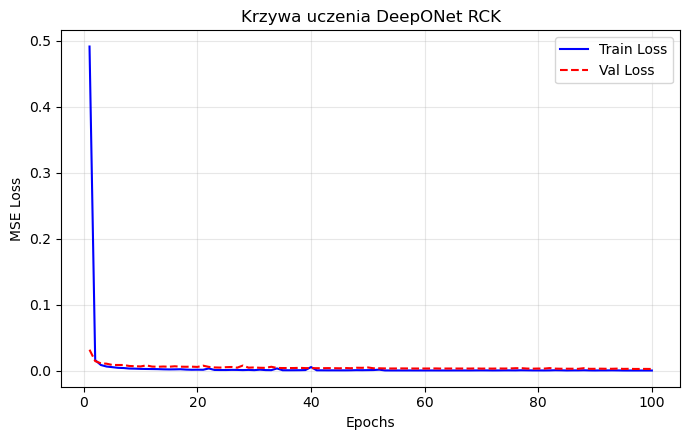

In [14]:
plt.figure(figsize=(7, 4.5))
plt.plot(range(1, FINAL_EPOCHS + 1), train_losses, label='Train Loss', color='blue', linewidth=1.5)
plt.plot(range(1, FINAL_EPOCHS + 1), val_losses, label='Val Loss', color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Krzywa uczenia DeepONet RCK')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save Plot 1
plot1_path = os.path.join(output_dir, "loss_history_DeepONet_RCK.png")
plt.savefig(plot1_path, dpi=300, bbox_inches='tight')
plt.show()

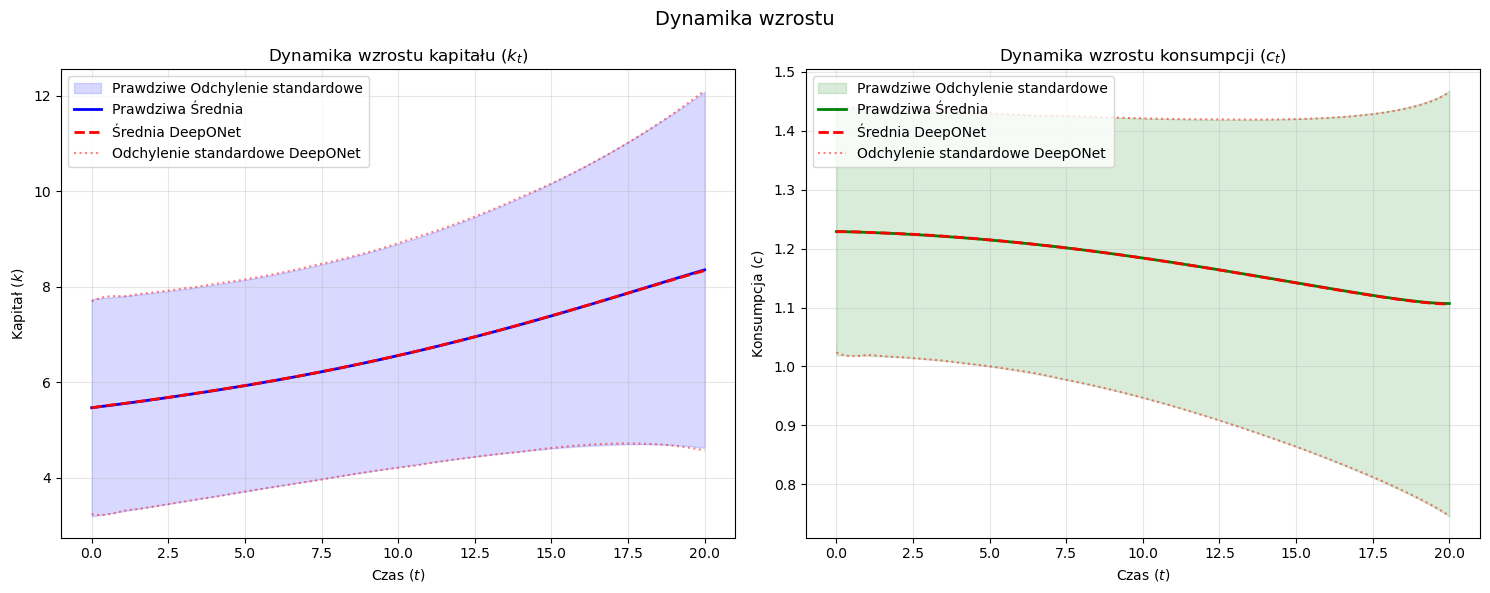

In [15]:
mean_target_k, mean_pred_k = targets_k.mean(axis=0), preds_k.mean(axis=0)
mean_target_c, mean_pred_c = targets_c.mean(axis=0), preds_c.mean(axis=0)
std_target_k, std_pred_k   = targets_k.std(axis=0), preds_k.std(axis=0)
std_target_c, std_pred_c   = targets_c.std(axis=0), preds_c.std(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Left Subplot: Capital ---
axes[0].fill_between(time_axis, mean_target_k - std_target_k, mean_target_k + std_target_k, 
                     color='blue', alpha=0.15, label='Prawdziwe Odchylenie standardowe')
axes[0].plot(time_axis, mean_target_k, color='blue', linewidth=2, label='Prawdziwa Średnia')
axes[0].plot(time_axis, mean_pred_k, color='red', linestyle='--', linewidth=2, label='Średnia DeepONet')
axes[0].plot(time_axis, mean_pred_k + std_pred_k, color='red', linestyle=':', alpha=0.5)
axes[0].plot(time_axis, mean_pred_k - std_pred_k, color='red', linestyle=':', alpha=0.5, label='Odchylenie standardowe DeepONet')
axes[0].set_title('Dynamika wzrostu kapitału ($k_t$)')
axes[0].set_xlabel('Czas ($t$)')
axes[0].set_ylabel('Kapitał ($k$)')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# --- Right Subplot: Consumption ---
axes[1].fill_between(time_axis, mean_target_c - std_target_c, mean_target_c + std_target_c, 
                     color='green', alpha=0.15, label='Prawdziwe Odchylenie standardowe')
axes[1].plot(time_axis, mean_target_c, color='green', linewidth=2, label='Prawdziwa Średnia')
axes[1].plot(time_axis, mean_pred_c, color='red', linestyle='--', linewidth=2, label='Średnia DeepONet')
axes[1].plot(time_axis, mean_pred_c + std_pred_c, color='red', linestyle=':', alpha=0.5)
axes[1].plot(time_axis, mean_pred_c - std_pred_c, color='red', linestyle=':', alpha=0.5, label='Odchylenie standardowe DeepONet')
axes[1].set_title('Dynamika wzrostu konsumpcji ($c_t$)')
axes[1].set_xlabel('Czas ($t$)')
axes[1].set_ylabel('Konsumpcja ($c$)')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Dynamika wzrostu', fontsize=14, y=0.98)
plt.tight_layout()

# Save Plot 2
plot2_path = os.path.join(output_dir, "RCK_DeepONet_growth_dynamics.png")
plt.savefig(plot2_path, dpi=300, bbox_inches='tight')
plt.show()

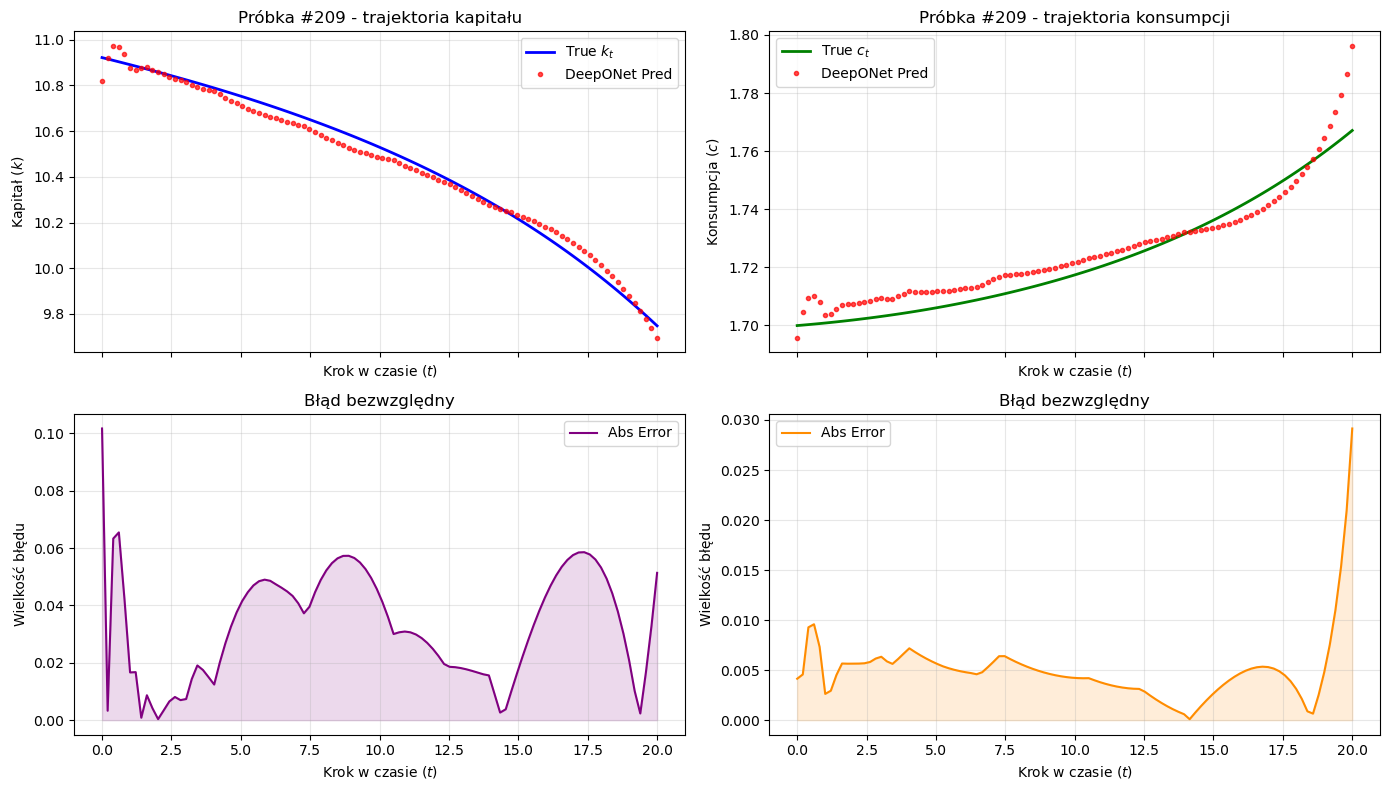

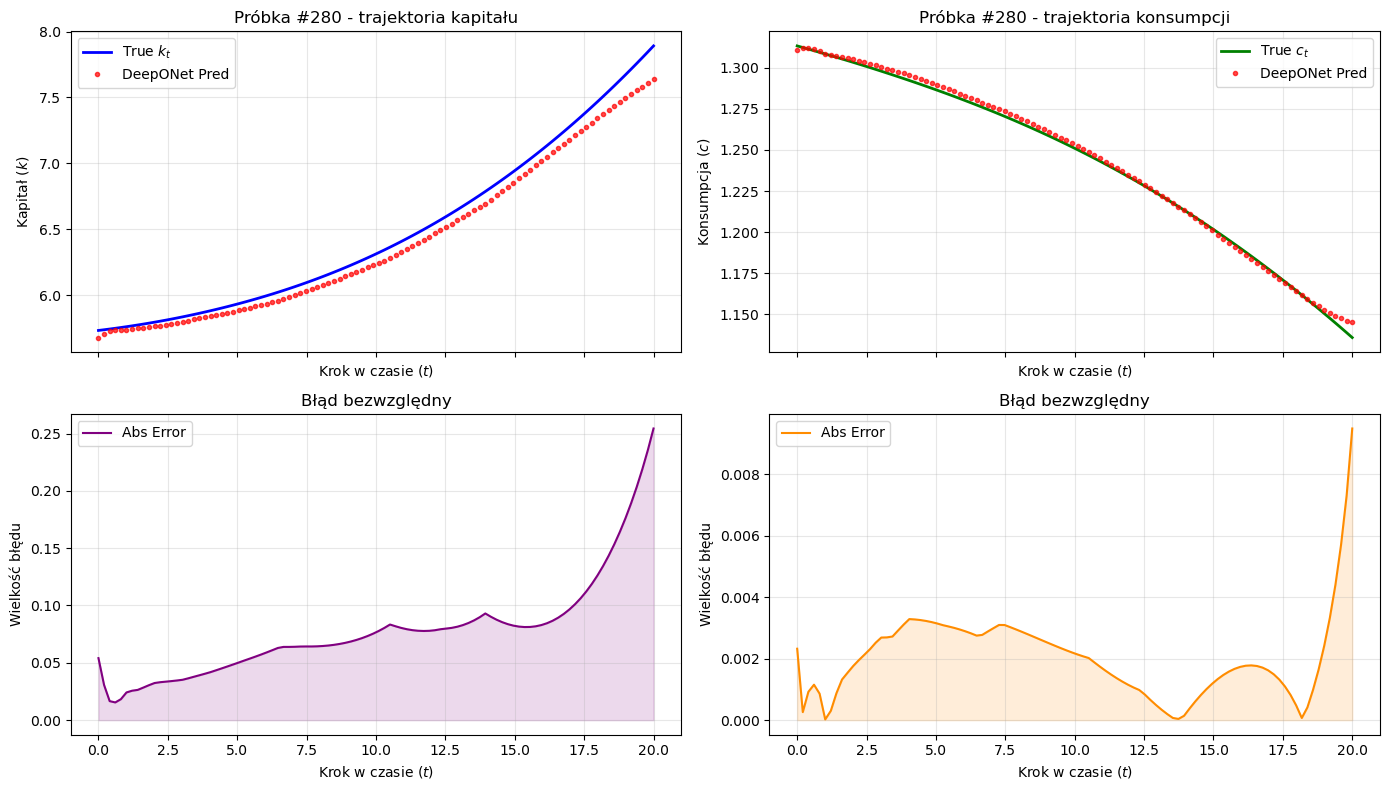

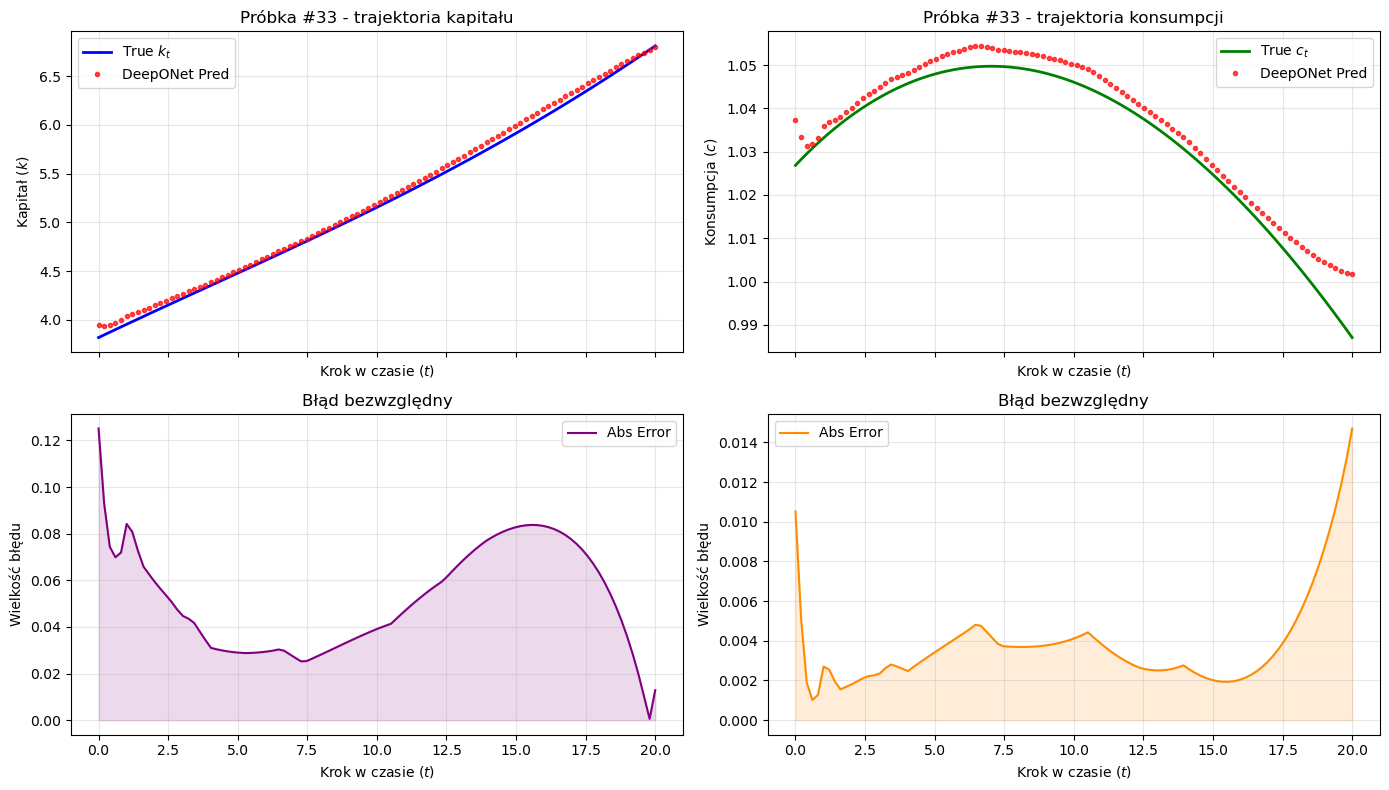

In [16]:
np.random.seed(42) 
random_indices = np.random.choice(len(all_preds), size=3, replace=False)

for sample_idx in random_indices:
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    
    # Top Left: Profiles
    axes[0, 0].plot(time_axis, targets_k[sample_idx], 'b-', linewidth=2, label='True $k_t$')
    axes[0, 0].plot(time_axis, preds_k[sample_idx], 'ro', markersize=3, alpha=0.7, label='DeepONet Pred')
    axes[0, 0].set_title(f'Próbka #{sample_idx} - trajektoria kapitału')
    axes[0, 0].set_ylabel('Kapitał ($k$)')
    axes[0, 0].set_xlabel('Krok w czasie ($t$)')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)
    
    # Bottom Left: Absolute Error
    axes[1, 0].fill_between(time_axis, abs_error_k[sample_idx], color='purple', alpha=0.15)
    axes[1, 0].plot(time_axis, abs_error_k[sample_idx], color='purple', linewidth=1.5, label='Abs Error')
    axes[1, 0].set_title('Błąd bezwzględny')
    axes[1, 0].set_xlabel('Krok w czasie ($t$)')
    axes[1, 0].set_ylabel('Wielkość błędu')
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)
    
    # Top Right: Profiles
    axes[0, 1].plot(time_axis, targets_c[sample_idx], 'g-', linewidth=2, label='True $c_t$')
    axes[0, 1].plot(time_axis, preds_c[sample_idx], 'ro', markersize=3, alpha=0.7, label='DeepONet Pred')
    axes[0, 1].set_title(f'Próbka #{sample_idx} - trajektoria konsumpcji')
    axes[0, 1].set_ylabel('Konsumpcja ($c$)')
    axes[0, 1].set_xlabel('Krok w czasie ($t$)')
    axes[0, 1].legend()
    axes[0, 1].grid(True, alpha=0.3)
    
    # Bottom Right: Absolute Error
    axes[1, 1].fill_between(time_axis, abs_error_c[sample_idx], color='darkorange', alpha=0.15)
    axes[1, 1].plot(time_axis, abs_error_c[sample_idx], color='darkorange', linewidth=1.5, label='Abs Error')
    axes[1, 1].set_title('Błąd bezwzględny')
    axes[1, 1].set_xlabel('Krok w czasie ($t$)')
    axes[1, 1].set_ylabel('Wielkość błędu')
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    # Save a separate plot file for each distinct sample checked
    plot3_path = os.path.join(output_dir, f"3_sample_{sample_idx}_analysis_DeepONet_RCK.png")
    plt.savefig(plot3_path, dpi=300, bbox_inches='tight')
    plt.show()